# Data Pre-Processing

#### Import the packages and the dataset

In [ ]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

schema = yaml.safe_load(open("../config/schema.yaml", "rb"))

df = pd.read_excel("../data/CreditWorthiness.xlsx", sheet_name="Data")
df = df.rename(columns=schema["raw_column_mapping"])

for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].str.replace(r"\s+", " ", regex=True).str.strip()

print(df.shape)

(1000, 21)


## Data Cleaning

### Handling the missing values

* Handling the missing values
* Handling the duplicates
* Checking the data types
* Understanding the dataset

#### Check the null values

In [ ]:
features_with_na = [feature for feature in df.columns if df[feature].isnull().sum() >= 1]
for feature in features_with_na:
    print(feature, np.round(df[feature].isnull().mean() * 100, 5), "% missing values")

features_with_na

[]

* **There are no null values in the dataset**

### Other data cleaning steps

**Handling the duplicates**

In [3]:
df.duplicated().sum()

np.int64(0)

* **No duplicates in the dataset**

**There is no identifier column to remove**

Unlike many credit datasets, this one carries no application id: every one of the 21 columns
describes the applicant or the requested credit, so nothing has to be dropped for that reason.

# Feature Engineering

## Feature Extraction

In [4]:
df.head()

,checking_balance,credit_duration,credit_history,credit_purpose,credit_amount,savings_balance,employment_duration,installment_rate,marital_status_gender,other_parties,residence_duration,property_type,age,installment_plans,housing_type,existing_credits,job_type,num_dependents,telephone,foreign_worker,credit_score
0,0 <= Rs. < 2000,9,all settled till now,Business,13790,Rs. < 1000,1 to 4 years,2,married or widowed male,no one,less than a year,real estate,27,bank,own,1,employee with official position,1,yes,no,good
1,0 <= Rs. < 2000,15,dues not paid earlier,electronics,15250,no savings account,more than 7 years,4,single male,"yes, guarantor",more than 3 years,real estate,50,none,own,2,employee with official position,1,yes,no,good
2,0 <= Rs. < 2000,36,none taken/all settled,Business,19410,Rs. < 1000,more than 7 years,4,single male,no one,more than 3 years,Unknown,61,none,free,1,"employed either in management, self or in high...",1,yes,no,bad
3,0 <= Rs. < 2000,48,none taken/all settled,Business,144090,Rs. < 1000,1 to 4 years,2,single male,no one,1 to 2 years,Other cars etc.,25,none,own,1,employee with official position,1,yes,no,bad
4,no checking account,24,all settled till now,electronics,31690,Rs. < 1000,less than 1 year,4,divorced or separated or married female,no one,more than 3 years,life insurance/building society,26,none,own,1,employee with official position,1,yes,no,good


**Combine the requested amount with the requested duration**

The EDA showed that `credit_amount` and `credit_duration` grow together, and that the applications
sitting above that trend, a large amount to be repaid over a short period, are the risky ones.
The ratio of the two columns expresses how much has to be repaid every month, which is exactly the
number a credit officer would compute by hand.

In [5]:
df["monthly_installment"] = df["credit_amount"] / df["credit_duration"]
df[["credit_amount", "credit_duration", "monthly_installment"]].head()

,credit_amount,credit_duration,monthly_installment
0,13790,9,1532.222222
1,15250,15,1016.666667
2,19410,36,539.166667
3,144090,48,3001.875000
4,31690,24,1320.416667


**Drop the column that carries no information**

The chi-squared test in the previous notebook showed that `telephone` is independent of the target,
and owning a telephone says nothing about the ability to repay a credit. This is the column listed
under `drop_columns` in `config/schema.yaml`.

In [6]:
df = df.drop(columns=schema["drop_columns"])
df.shape

(1000, 21)

### Type of the features

**Numeric features**

In [7]:
num_features = [feature for feature in df.columns if df[feature].dtype != "O"]
print("Num of Numerical Features :", len(num_features))
num_features

Num of Numerical Features : 7


['credit_duration',
 'credit_amount',
 'installment_rate',
 'age',
 'existing_credits',
 'num_dependents',
 'monthly_installment']

**Categorical features**

In [8]:
cat_features = [feature for feature in df.columns if df[feature].dtype == "O"]
print("Num of Categorical Features :", len(cat_features))
cat_features

Num of Categorical Features : 14


['checking_balance',
 'credit_history',
 'credit_purpose',
 'savings_balance',
 'employment_duration',
 'marital_status_gender',
 'other_parties',
 'residence_duration',
 'property_type',
 'installment_plans',
 'housing_type',
 'job_type',
 'foreign_worker',
 'credit_score']

**Discrete features**

In [9]:
discrete_features = [feature for feature in num_features if len(df[feature].unique()) <= 25]
print("Num of Discrete Features :", len(discrete_features))
discrete_features

Num of Discrete Features : 3


['installment_rate', 'existing_credits', 'num_dependents']

**Continuous features**

In [10]:
continuous_features = [feature for feature in num_features if feature not in discrete_features]
print("Num of Continuous Features :", len(continuous_features))
continuous_features

Num of Continuous Features : 4


['credit_duration', 'credit_amount', 'age', 'monthly_installment']

### Split X and y

* **Split the dataframe into X and y**
* **X holds the independent columns and y holds the dependent column, `credit_score`.**

In [11]:
X = df.drop("credit_score", axis=1)
y = df["credit_score"]
y.head()

0    good
1    good
2     bad
3     bad
4    good
Name: credit_score, dtype: object

**Manual encoding of the target column**

In [ ]:
y = np.where(y == "bad", 1, 0)
y[:20]

array([0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0])

In [13]:
print("Share of the positive class (bad credit score):", round(y.mean(), 3))

Share of the positive class (bad credit score): 0.3


## Feature Transformation

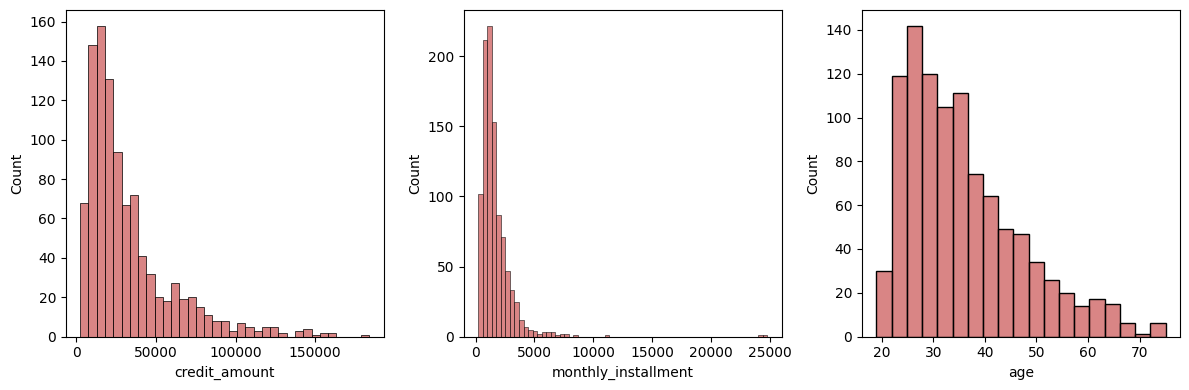

In [ ]:
plt.figure(figsize=(12, 4))
for i, col in enumerate(["credit_amount", "monthly_installment", "age"]):
    plt.subplot(1, 3, i + 1)
    sns.histplot(x=X[col], color="indianred")
    plt.xlabel(col)
    plt.tight_layout()

* `credit_amount`, `monthly_installment` and `age` are skewed
* Apply a power transform featurewise to make the data more Gaussian-like.

Power transforms are a family of parametric, monotonic transformations that are applied to make data
more Gaussian-like. This is useful for modeling issues related to heteroscedasticity (non-constant
variance), or other situations where normality is desired.

Currently, PowerTransformer supports the Box-Cox transform and the Yeo-Johnson transform.

**Checking the skewness**

**What is skewness?**

* Skewness refers to a distortion or asymmetry that deviates from the symmetrical bell curve, or
normal distribution, in a set of data. If the curve is shifted to the left or to the right, it is
said to be skewed. Skewness can be quantified as a representation of the extent to which a given
distribution varies from a normal distribution. A normal distribution has a skew of zero.

In [ ]:
X[num_features].skew(axis=0, skipna=True)

credit_duration        1.094184
credit_amount          1.949628
installment_rate      -0.531348
age                    1.020739
existing_credits       1.272576
num_dependents         1.909445
monthly_installment    7.632114
dtype: float64

- Positively skewed: `monthly_installment` (7.6), `credit_amount` (1.9), `age` (1.0).
- `monthly_installment` is by far the worst, which is expected from a ratio.

## Apply the Power Transformer to check whether it reduces the skewness

In [16]:
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method="yeo-johnson")
transform_features = schema["transform_columns"]
X_copy = pt.fit_transform(X[transform_features])
X_copy = pd.DataFrame(X_copy, columns=transform_features)
transform_features

['credit_amount', 'monthly_installment', 'age']

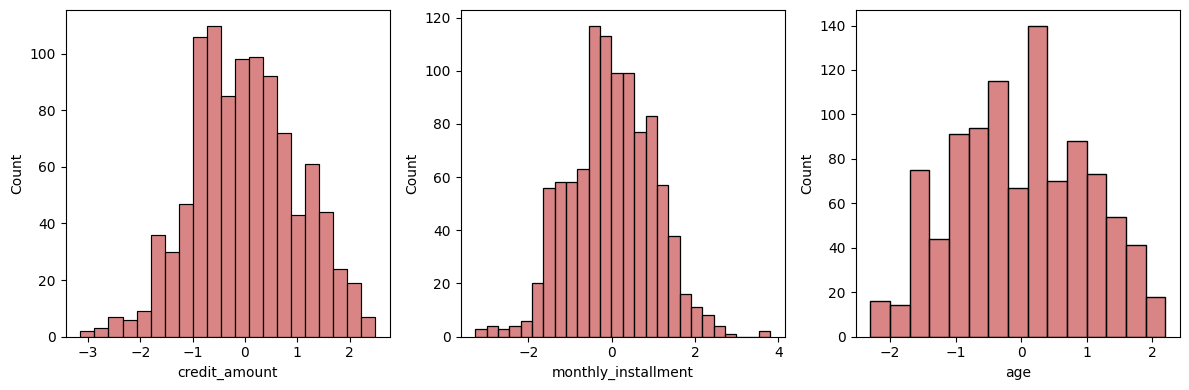

In [17]:
plt.figure(figsize=(12, 4))
for i, col in enumerate(transform_features):
    plt.subplot(1, 3, i + 1)
    sns.histplot(x=X_copy[col], color="indianred")
    plt.xlabel(col)
    plt.tight_layout()

**Checking the skewness again**

In [18]:
X_copy.skew(axis=0, skipna=True)

credit_amount          0.004669
monthly_installment   -0.007744
age                    0.056496
dtype: float64

- Yeo-Johnson is used here because it supports both positive and negative data.
- The skewness drops close to zero for all three columns, so the Power Transformer with Yeo-Johnson is used in the pipeline.

In [19]:
for feature in cat_features:
    print(feature, ":", df[feature].nunique())

checking_balance : 4
credit_history : 4
credit_purpose : 10
savings_balance : 5
employment_duration : 5
marital_status_gender : 4
other_parties : 3
residence_duration : 4
property_type : 4
installment_plans : 3
housing_type : 3
job_type : 4
foreign_worker : 2
credit_score : 2


## Feature Encoding and Scaling

**One Hot Encoding for the nominal columns**
* One hot encoding is a process by which categorical variables are converted into a form that could
  be provided to ML algorithms to do a better job in prediction.

**Ordinal Encoding for the columns whose levels have a natural order**
* Ordinal encoding is used for an ordinal variable, that is a variable which comprises a finite set
  of discrete values with a ranked ordering between them.
* `checking_balance`, `savings_balance`, `employment_duration` and `residence_duration` are ordered
  ranges, so the order is given explicitly to the encoder through `ordinal_categories` in
  `config/schema.yaml` instead of letting it fall back to the alphabetical order.

**Standard Scaler**
* Standardize the features by removing the mean and scaling to unit variance.

**Power Transformer**
* Power transforms are a technique for transforming numerical input or output variables to have a
  Gaussian or a more Gaussian-like probability distribution.

### **Preprocessing using a Column Transformer**

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PowerTransformer, StandardScaler

or_columns = schema["or_columns"]
oh_columns = schema["oh_columns"]
transform_columns = schema["transform_columns"]
num_columns = schema["num_features"]
ordinal_categories = schema["ordinal_categories"]

print("ordinal    :", or_columns)
print("one hot    :", oh_columns)
print("power      :", transform_columns)
print("standardise:", num_columns)


def build_preprocessor():
    numeric_transformer = StandardScaler()
    oh_transformer = OneHotEncoder(handle_unknown="ignore")
    ordinal_encoder = OrdinalEncoder(
        categories=[ordinal_categories[column] for column in or_columns],
        handle_unknown="use_encoded_value",
        unknown_value=-1,
    )
    transform_pipe = Pipeline(steps=[("transformer", PowerTransformer(method="yeo-johnson"))])

    return ColumnTransformer(
        [
            ("OneHotEncoder", oh_transformer, oh_columns),
            ("Ordinal_Encoder", ordinal_encoder, or_columns),
            ("Transformer", transform_pipe, transform_columns),
            ("StandardScaler", numeric_transformer, num_columns),
        ]
    )

ordinal    : ['checking_balance', 'savings_balance', 'employment_duration', 'residence_duration', 'foreign_worker']
one hot    : ['credit_history', 'credit_purpose', 'marital_status_gender', 'other_parties', 'property_type', 'installment_plans', 'housing_type', 'job_type']
power      : ['credit_amount', 'monthly_installment', 'age']
standardise: ['credit_duration', 'credit_amount', 'installment_rate', 'age', 'existing_credits', 'num_dependents', 'monthly_installment']


### Train test split **before** the preprocessing

The preprocessor learns the means, the variances and the power transform parameters from the data.
Fitting it on the whole dataset would leak information from the test set into the training set, so
the split comes first and the preprocessor is fitted on the training part only.

The split is stratified, so that both parts keep the original 70/30 class balance.

In [21]:
from sklearn.model_selection import train_test_split

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = build_preprocessor()
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("train:", X_train.shape, " test:", X_test.shape)
print("share of bad scores - train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

train: (800, 50)  test: (200, 50)
share of bad scores - train: 0.3  test: 0.3


# Classification

## Handling the imbalanced target

The training set holds 70% good scores and 30% bad ones. A model trained on it tends to play safe
and answer "good" too often, so the minority class is resampled. Two techniques are compared here:

* **SMOTE** creates synthetic examples of the minority class until both classes have the same size.
* **SMOTEENN** does the same and then removes, with an Edited Nearest Neighbours filter, the samples
  whose neighbours disagree with them.

Only the **training** set is resampled. The test set is left exactly as it is, otherwise the reported
scores would describe an artificial population instead of the real applicants.

In [22]:
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import SMOTE

resamplers = {
    "none": None,
    "SMOTE": SMOTE(random_state=42),
    "SMOTEENN": SMOTEENN(random_state=42, sampling_strategy="minority"),
}

for name, resampler in resamplers.items():
    if resampler is None:
        size, positive = len(y_train), y_train.mean()
    else:
        _, y_res = resampler.fit_resample(X_train, y_train)
        size, positive = len(y_res), y_res.mean()
    print(f"{name:9s} training rows: {size:5d}   share of bad scores: {positive:.2f}")

none      training rows:   800   share of bad scores: 0.30


SMOTE     training rows:  1120   share of bad scores: 0.50
SMOTEENN  training rows:   640   share of bad scores: 0.68


## Model training

* The train-test split procedure is used to estimate the performance of machine learning algorithms
  when they are used to make predictions on data not used to train the model.
* It is a fast and easy procedure to perform, the results of which allow you to compare the
  performance of machine learning algorithms.

In [23]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

In [ ]:
def evaluate_clf(true, predicted):
    acc = accuracy_score(true, predicted)
    f1 = f1_score(true, predicted)
    precision = precision_score(true, predicted, zero_division=0)
    recall = recall_score(true, predicted)
    roc_auc = roc_auc_score(true, predicted)
    return acc, f1, precision, recall, roc_auc

In [25]:
models = {
    "Random Forest": RandomForestClassifier(random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "K-Neighbors Classifier": KNeighborsClassifier(),
    "XGBClassifier": XGBClassifier(eval_metric="logloss"),
    "CatBoosting Classifier": CatBoostClassifier(verbose=False, random_state=42),
    "Support Vector Classifier": SVC(),
    "AdaBoost Classifier": AdaBoostClassifier(random_state=42),
}

In [ ]:
def evaluate_models(X_train, y_train, X_test, y_test, models, verbose=True):
    '''
    This function takes the already split train and test sets and a models dictionary as input.
    It iterates through the given model dictionary, evaluates the metrics on both sets and
    returns a dataframe holding the report of every model.
    '''
    rows = []

    for name, model in models.items():
        model.fit(X_train, y_train)

        y_train_pred = model.predict(X_train)
        y_test_pred = model.predict(X_test)

        train_acc, train_f1, train_precision, train_recall, train_roc = evaluate_clf(y_train, y_train_pred)

        test_acc, test_f1, test_precision, test_recall, test_roc = evaluate_clf(y_test, y_test_pred)

        if verbose:
            print(name)
            print("Model performance for the Training set")
            print("- Accuracy: {:.4f}".format(train_acc))
            print("- F1 score: {:.4f}".format(train_f1))
            print("- Precision: {:.4f}".format(train_precision))
            print("- Recall: {:.4f}".format(train_recall))
            print("- Roc Auc Score: {:.4f}".format(train_roc))
            print("----------------------------------")
            print("Model performance for the Test set")
            print("- Accuracy: {:.4f}".format(test_acc))
            print("- F1 score: {:.4f}".format(test_f1))
            print("- Precision: {:.4f}".format(test_precision))
            print("- Recall: {:.4f}".format(test_recall))
            print("- Roc Auc Score: {:.4f}".format(test_roc))
            print("=" * 35)
            print("\n")

        rows.append(
            {
                "Model Name": name,
                "Accuracy": test_acc,
                "F1": test_f1,
                "Precision": test_precision,
                "Recall": test_recall,
                "Roc Auc": test_roc,
            }
        )

    return pd.DataFrame(rows).sort_values(by=["F1"], ascending=False).reset_index(drop=True)

### Baseline: models trained on the untouched, imbalanced training set

In [27]:
base_model_report = evaluate_models(X_train, y_train, X_test, y_test, models)

Random Forest
Model performance for the Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for the Test set
- Accuracy: 0.7600
- F1 score: 0.4783
- Precision: 0.6875
- Recall: 0.3667
- Roc Auc Score: 0.6476


Decision Tree
Model performance for the Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for the Test set
- Accuracy: 0.6800
- F1 score: 0.4576
- Precision: 0.4655
- Recall: 0.4500
- Roc Auc Score: 0.6143




Gradient Boosting
Model performance for the Training set
- Accuracy: 0.9250
- F1 score: 0.8624
- Precision: 0.9592
- Recall: 0.7833
- Roc Auc Score: 0.8845
----------------------------------
Model performance for the Test set
- Accuracy: 0.7150
- F1 score: 0.5210
- Precision: 0.5254
- Recall: 0.5167
- Roc Auc Score: 0.6583


Logistic Regression
Model performance for the Training set
- Accuracy: 0.7600
- F1 score: 0.5176
- Precision: 0.6519
- Recall: 0.4292
- Roc Auc Score: 0.6655
----------------------------------
Model performance for the Test set
- Accuracy: 0.6850
- F1 score: 0.4522
- Precision: 0.4727
- Recall: 0.4333
- Roc Auc Score: 0.6131


K-Neighbors Classifier
Model performance for the Training set
- Accuracy: 0.7975
- F1 score: 0.5930
- Precision: 0.7468
- Recall: 0.4917
- Roc Auc Score: 0.7101
----------------------------------
Model performance for the Test set
- Accuracy: 0.7150
- F1 score: 0.4466
- Precision: 0.5349
- Recall: 0.3833
- Roc Auc Score: 0.6202




XGBClassifier
Model performance for the Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for the Test set
- Accuracy: 0.7650
- F1 score: 0.5913
- Precision: 0.6182
- Recall: 0.5667
- Roc Auc Score: 0.7083




CatBoosting Classifier
Model performance for the Training set
- Accuracy: 0.9700
- F1 score: 0.9474
- Precision: 1.0000
- Recall: 0.9000
- Roc Auc Score: 0.9500
----------------------------------
Model performance for the Test set
- Accuracy: 0.7650
- F1 score: 0.5766
- Precision: 0.6275
- Recall: 0.5333
- Roc Auc Score: 0.6988


Support Vector Classifier
Model performance for the Training set
- Accuracy: 0.8150
- F1 score: 0.5819
- Precision: 0.9035
- Recall: 0.4292
- Roc Auc Score: 0.7048
----------------------------------
Model performance for the Test set
- Accuracy: 0.7700
- F1 score: 0.4524
- Precision: 0.7917
- Recall: 0.3167
- Roc Auc Score: 0.6405




AdaBoost Classifier
Model performance for the Training set
- Accuracy: 0.7762
- F1 score: 0.5468
- Precision: 0.6968
- Recall: 0.4500
- Roc Auc Score: 0.6830
----------------------------------
Model performance for the Test set
- Accuracy: 0.7300
- F1 score: 0.5091
- Precision: 0.5600
- Recall: 0.4667
- Roc Auc Score: 0.6548




**Results of all the models**

In [28]:
base_model_report

,Model Name,Accuracy,F1,Precision,Recall,Roc Auc
0,XGBClassifier,0.765,0.591304,0.618182,0.566667,0.708333
1,CatBoosting Classifier,0.765,0.576577,0.627451,0.533333,0.698810
2,Gradient Boosting,0.715,0.521008,0.525424,0.516667,0.658333
3,AdaBoost Classifier,0.730,0.509091,0.560000,0.466667,0.654762
4,Random Forest,0.760,0.478261,0.687500,0.366667,0.647619
5,Decision Tree,0.680,0.457627,0.465517,0.450000,0.614286
6,Support Vector Classifier,0.770,0.452381,0.791667,0.316667,0.640476
7,Logistic Regression,0.685,0.452174,0.472727,0.433333,0.613095
8,K-Neighbors Classifier,0.715,0.446602,0.534884,0.383333,0.620238


### Which resampling technique should the pipeline use?

The same nine models are now trained on the SMOTE and on the SMOTEENN version of the training set,
and always scored against the same untouched test set. This is the experiment that decides what
`data_transformation.py` does.

In [29]:
comparison = {}

for name, resampler in resamplers.items():
    if resampler is None:
        X_res, y_res = X_train, y_train
    else:
        X_res, y_res = resampler.fit_resample(X_train, y_train)

    fresh_models = {
        "Random Forest": RandomForestClassifier(random_state=42),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "K-Neighbors Classifier": KNeighborsClassifier(),
        "XGBClassifier": XGBClassifier(eval_metric="logloss"),
        "CatBoosting Classifier": CatBoostClassifier(verbose=False, random_state=42),
        "Support Vector Classifier": SVC(),
        "AdaBoost Classifier": AdaBoostClassifier(random_state=42),
    }

    report = evaluate_models(X_res, y_res, X_test, y_test, fresh_models, verbose=False)
    report.insert(1, "Resampling", name)
    comparison[name] = report

comparison_report = pd.concat(comparison.values(), ignore_index=True)
comparison_report.sort_values(by="F1", ascending=False).head(12)

,Model Name,Resampling,Accuracy,F1,Precision,Recall,Roc Auc
18,Gradient Boosting,SMOTEENN,0.680,0.619048,0.481481,0.866667,0.733333
19,CatBoosting Classifier,SMOTEENN,0.655,0.610169,0.461538,0.900000,0.725000
9,CatBoosting Classifier,SMOTE,0.760,0.606557,0.596774,0.616667,0.719048
20,AdaBoost Classifier,SMOTEENN,0.655,0.601156,0.460177,0.866667,0.715476
10,AdaBoost Classifier,SMOTE,0.705,0.593103,0.505882,0.716667,0.708333
0,XGBClassifier,none,0.765,0.591304,0.618182,0.566667,0.708333
11,XGBClassifier,SMOTE,0.755,0.588235,0.593220,0.583333,0.705952
21,Random Forest,SMOTEENN,0.650,0.588235,0.454545,0.833333,0.702381
12,Gradient Boosting,SMOTE,0.740,0.587302,0.560606,0.616667,0.704762
1,CatBoosting Classifier,none,0.765,0.576577,0.627451,0.533333,0.698810


In [30]:
summary = comparison_report.groupby("Resampling")[["Accuracy", "F1", "Roc Auc"]].mean().round(3)
summary.loc[["none", "SMOTE", "SMOTEENN"]]

,Accuracy,F1,Roc Auc
Resampling,,,
none,0.732,0.498,0.651
SMOTE,0.702,0.560,0.682
SMOTEENN,0.617,0.569,0.681


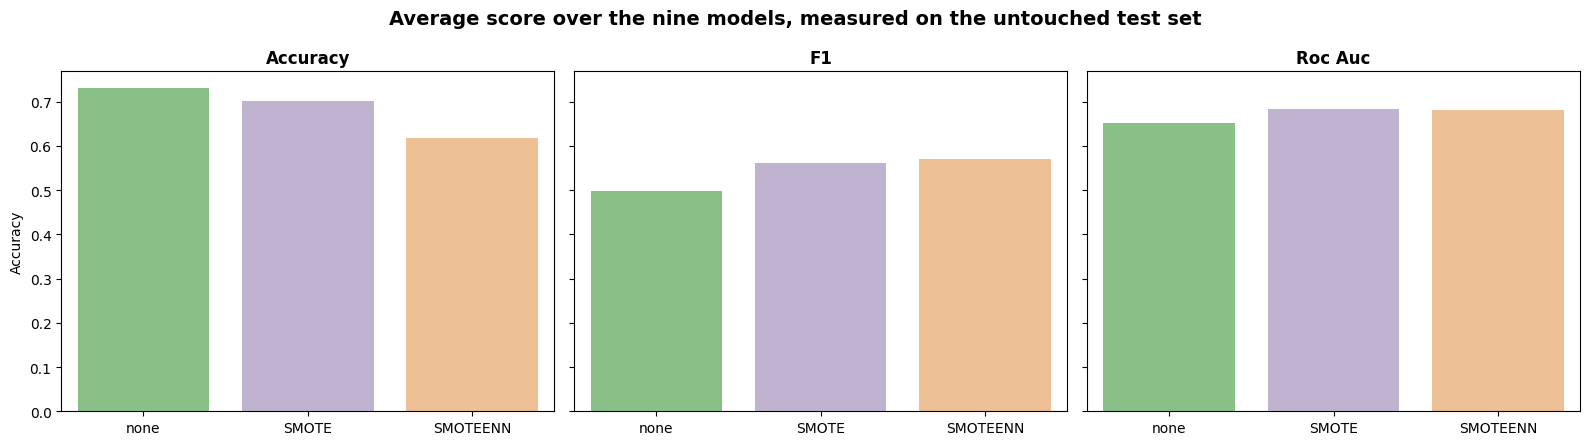

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, metric in zip(axes, ["Accuracy", "F1", "Roc Auc"]):
    sns.barplot(data=comparison_report, x="Resampling", y=metric, ax=ax,
                order=["none", "SMOTE", "SMOTEENN"], palette="Accent", errorbar=None)
    ax.set_title(metric, fontweight="bold")
    ax.set_xlabel("")
fig.suptitle("Average score over the nine models, measured on the untouched test set",
             fontsize=14, fontweight="bold")
fig.tight_layout()

**Report**
* Without any resampling the models reach the best accuracy but the worst recall: they simply answer
  "good" too often, and half of the bad applicants slip through.
* **SMOTE** keeps the accuracy close to the baseline while lifting the F1 score, which is the metric
  that matters here because the positive class is the rare and expensive one.
* **SMOTEENN** resamples so aggressively that the training distribution stops resembling the real
  population, and both the accuracy and the ROC AUC collapse on the untouched test set.

**SMOTE is therefore the technique used by `credit_worthiness/components/data_transformation.py`.**

In [32]:
smt = SMOTE(random_state=42)
X_train_res, y_train_res = smt.fit_resample(X_train, y_train)
print("resampled training set:", X_train_res.shape)

resampled training set: (1120, 50)


## Hyperparameter tuning

**Define the parameter grids of the three most promising models**

In [33]:
rf_params = {
    "max_depth": [10, 15, 20, None],
    "max_features": ["sqrt", "log2"],
    "n_estimators": [100, 200],
}

gb_params = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
}

lr_params = {
    "C": [0.01, 0.1, 1.0, 10.0],
}

In [ ]:
randomcv_models = [
    ("RF", RandomForestClassifier(random_state=42), rf_params),
    ("GB", GradientBoostingClassifier(random_state=42), gb_params),
    ("LR", LogisticRegression(max_iter=1000, random_state=42), lr_params),
]

**Search the best parameters, scoring on the F1 of the positive class**

In [35]:
from sklearn.model_selection import GridSearchCV

model_param = {}
for name, model, params in randomcv_models:
    search = GridSearchCV(estimator=model, param_grid=params, cv=3, scoring="f1", n_jobs=-1, verbose=0)
    search.fit(X_train_res, y_train_res)
    model_param[name] = search.best_params_
    print(f"---------------- Best Params for {name} -------------------")
    print(search.best_params_, " cv f1:", round(search.best_score_, 4))

---------------- Best Params for RF -------------------
{'max_depth': 20, 'max_features': 'log2', 'n_estimators': 100}  cv f1: 0.8043


---------------- Best Params for GB -------------------
{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100}  cv f1: 0.7878
---------------- Best Params for LR -------------------
{'C': 10.0}  cv f1: 0.7289


In [36]:
model_param

{'RF': {'max_depth': 20, 'max_features': 'log2', 'n_estimators': 100},
 'GB': {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 100},
 'LR': {'C': 10.0}}

## Retraining the models with the best parameters

In [37]:
best_models = {
    "Random Forest Classifier": RandomForestClassifier(**model_param["RF"], random_state=42),
    "Gradient Boosting Classifier": GradientBoostingClassifier(**model_param["GB"], random_state=42),
    "Logistic Regression": LogisticRegression(**model_param["LR"], max_iter=1000, random_state=42),
}
tuned_report = evaluate_models(X_train_res, y_train_res, X_test, y_test, best_models)

Random Forest Classifier
Model performance for the Training set
- Accuracy: 1.0000
- F1 score: 1.0000
- Precision: 1.0000
- Recall: 1.0000
- Roc Auc Score: 1.0000
----------------------------------
Model performance for the Test set
- Accuracy: 0.7700
- F1 score: 0.5660
- Precision: 0.6522
- Recall: 0.5000
- Roc Auc Score: 0.6929




Gradient Boosting Classifier
Model performance for the Training set
- Accuracy: 0.9723
- F1 score: 0.9722
- Precision: 0.9766
- Recall: 0.9679
- Roc Auc Score: 0.9723
----------------------------------
Model performance for the Test set
- Accuracy: 0.7450
- F1 score: 0.5920
- Precision: 0.5692
- Recall: 0.6167
- Roc Auc Score: 0.7083


Logistic Regression
Model performance for the Training set
- Accuracy: 0.7661
- F1 score: 0.7661
- Precision: 0.7661
- Recall: 0.7661
- Roc Auc Score: 0.7661
----------------------------------
Model performance for the Test set
- Accuracy: 0.6500
- F1 score: 0.5625
- Precision: 0.4500
- Recall: 0.7500
- Roc Auc Score: 0.6786




In [38]:
tuned_report

,Model Name,Accuracy,F1,Precision,Recall,Roc Auc
0,Gradient Boosting Classifier,0.745,0.592000,0.569231,0.616667,0.708333
1,Random Forest Classifier,0.770,0.566038,0.652174,0.500000,0.692857
2,Logistic Regression,0.650,0.562500,0.450000,0.750000,0.678571


These three models, with these three grids, are exactly what `config/model.yaml` hands over to
the `ModelFactory` of the training pipeline, so the notebook and the pipeline explore the same space.

## The final model

In [39]:
best_name = tuned_report.iloc[0]["Model Name"]
best_model = best_models[best_name]
y_pred = best_model.predict(X_test)

print(f"FINAL MODEL '{best_name}'")
print("Accuracy Score value: {:.4f}".format(accuracy_score(y_test, y_pred)))
print("F1 Score value      : {:.4f}".format(f1_score(y_test, y_pred)))
print()
print(classification_report(y_test, y_pred, target_names=["good", "bad"]))

FINAL MODEL 'Gradient Boosting Classifier'
Accuracy Score value: 0.7450
F1 Score value      : 0.5920

              precision    recall  f1-score   support

        good       0.83      0.80      0.81       140
         bad       0.57      0.62      0.59        60

    accuracy                           0.74       200
   macro avg       0.70      0.71      0.70       200
weighted avg       0.75      0.74      0.75       200



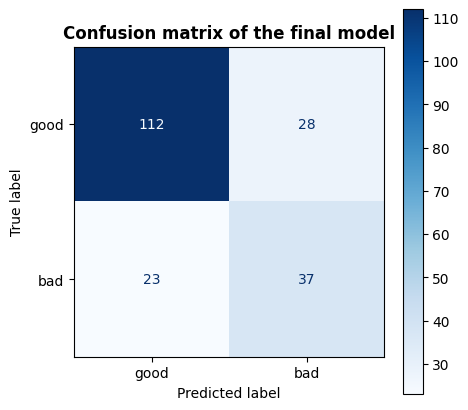

In [40]:
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=["good", "bad"], cmap="Blues", ax=ax)
plt.title("Confusion matrix of the final model", fontweight="bold")
plt.show()

**Reading the confusion matrix**

The bottom left cell counts the applicants who were scored as bad by the bank but accepted by the
model. Those are the expensive mistakes, every one of them is a credit that is unlikely to come back.

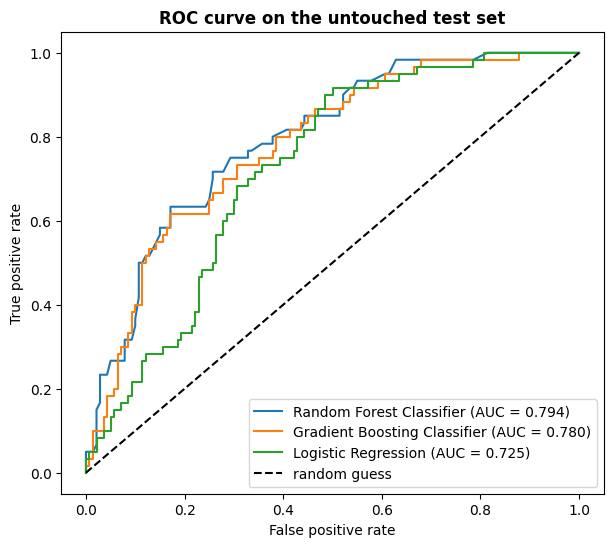

In [41]:
plt.figure(figsize=(7, 6))
for name, model in best_models.items():
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, scores)
        plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, scores):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve on the untouched test set", fontweight="bold")
plt.legend(loc="lower right")
plt.show()

## Which features drive the decision?

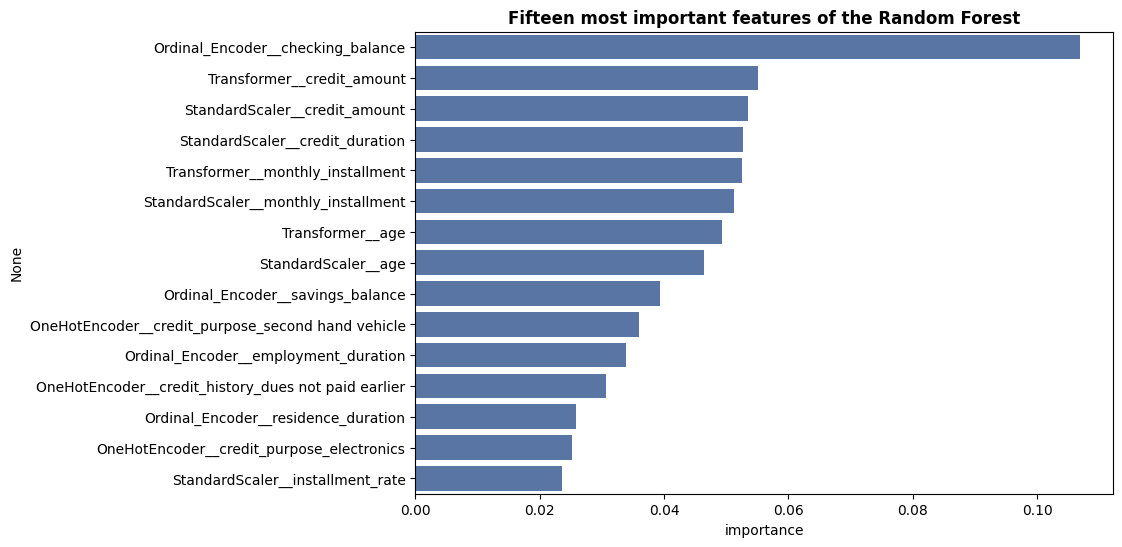

In [42]:
feature_names = preprocessor.get_feature_names_out()
forest = best_models["Random Forest Classifier"]

importances = pd.Series(forest.feature_importances_, index=feature_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=importances.values, y=importances.index, color="#4c72b0")
plt.title("Fifteen most important features of the Random Forest", fontweight="bold")
plt.xlabel("importance")
plt.show()

**Report**
* The balance of the current account, the requested amount, the duration and the derived
  `monthly_installment` dominate the decision, which confirms the intuition built during the EDA.
* `monthly_installment`, the column created in the feature engineering step, ends up among the most
  important features, so the extraction was worth it.

## Conclusion

* The best model is the one reported above, trained on a SMOTE balanced training set and measured on
  a test set that was never resampled.
* An accuracy around 0.77 with a recall around 0.5 on the minority class is a realistic result for
  this dataset of one thousand applications, and it is far more trustworthy than the numbers one
  obtains by resampling the test set as well.
* The whole recipe of this notebook, the column mapping, the derived feature, the encoders, the
  resampling and the model grids, is what the production pipeline executes in
  `credit_worthiness/components`, driven by `config/schema.yaml` and `config/model.yaml`.